# ========================================
# 04B_Insights_Visualization.ipynb
# ========================================

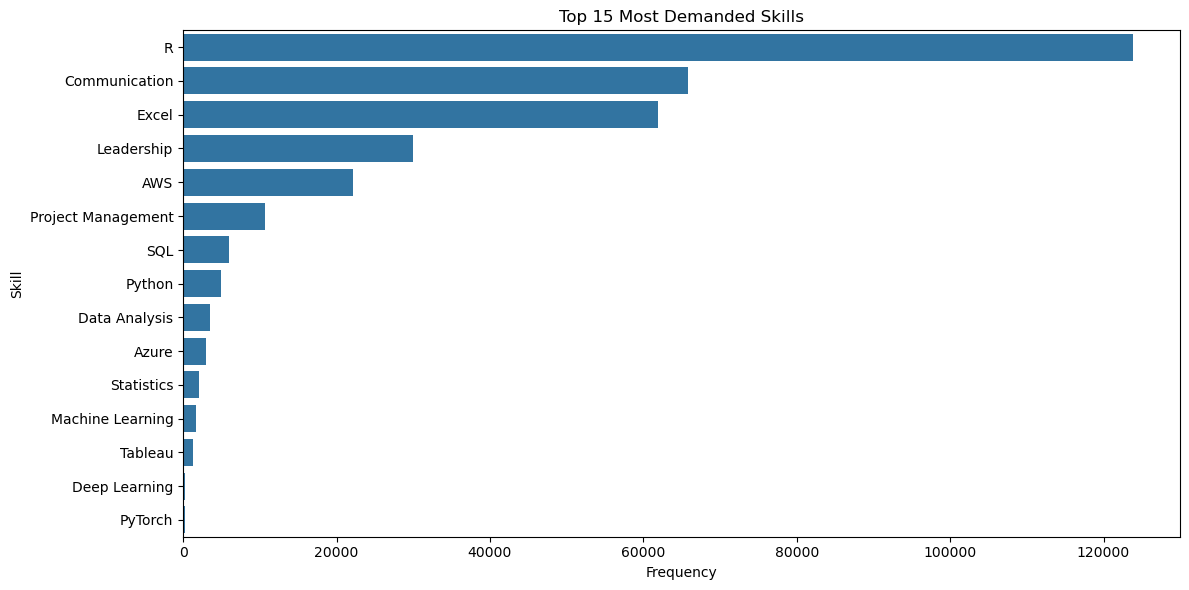

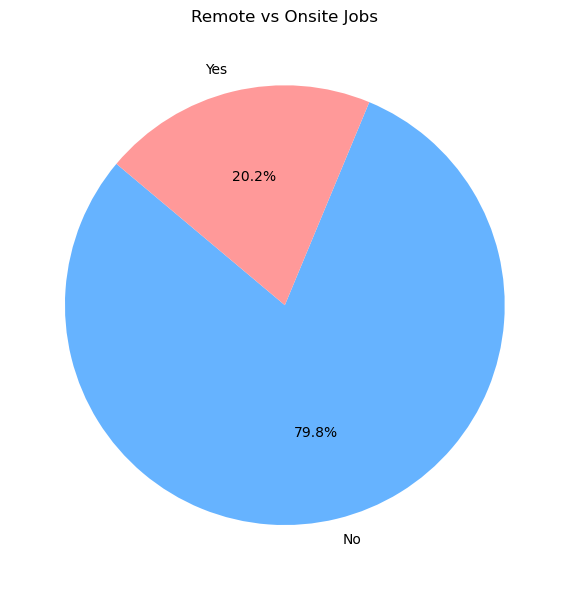

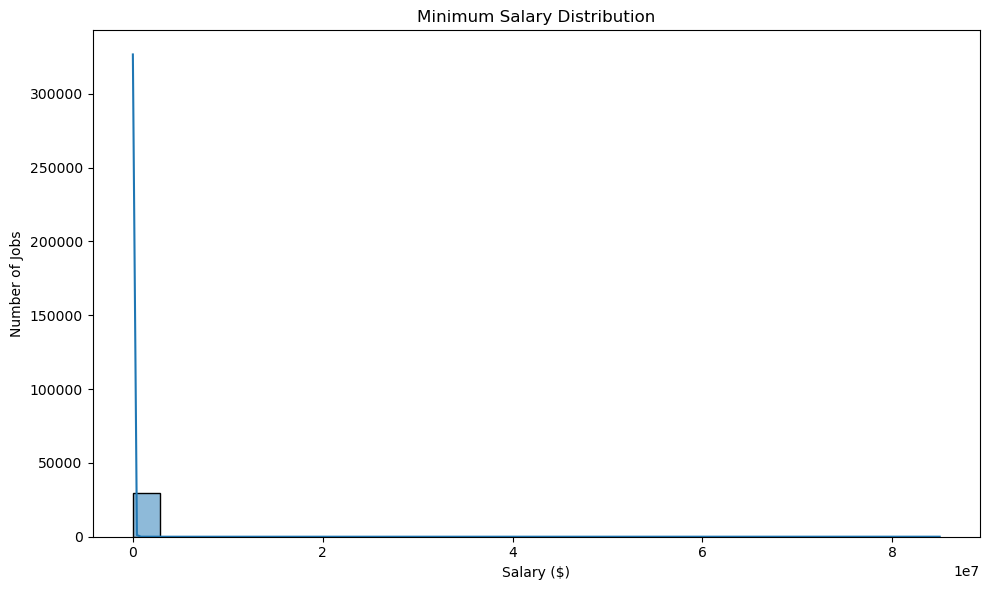

/var/folders/2v/418w7x5d03g34d38xmfssx8h0000gn/T/ipykernel_16166/3223672031.py:80: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='Cluster', data=df, palette="tab10")


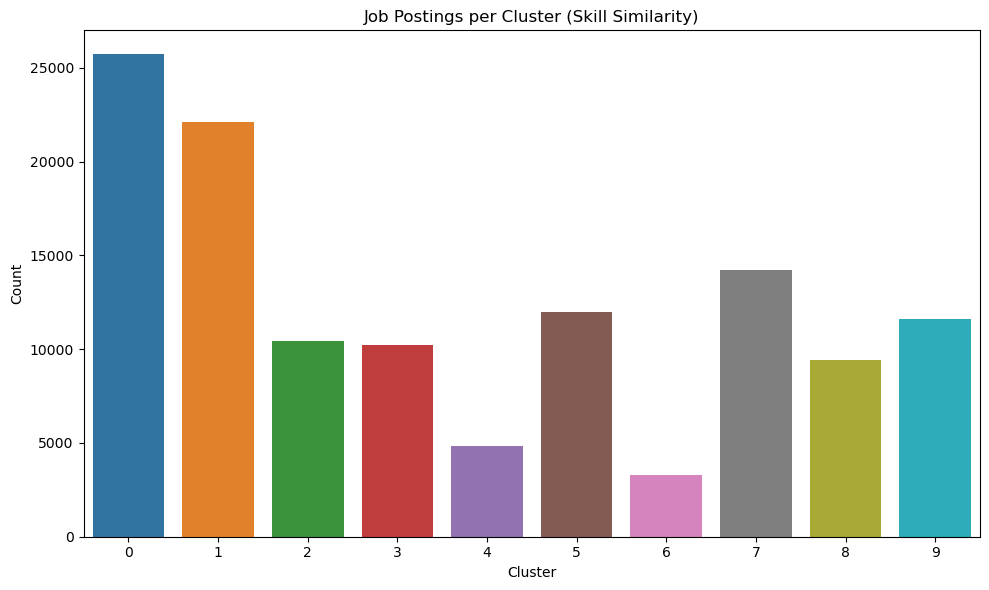


✅ All insights plots saved to outputs/plots/


In [5]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from ast import literal_eval

# 1. Load clustered data
df = pd.read_csv('/Users/ronitgandhi/Portfolio Projects/job_postings_insights/outputs/extracted_data/final_structured_job_postings_with_clusters.csv')

# --------------------------------------------
# Top Skills Analysis
# --------------------------------------------

# Flatten all skills into one list
all_skills = []
for skills in df['Skills']:
    try:
        skills_list = literal_eval(skills) if isinstance(skills, str) else []
        all_skills.extend(skills_list)
    except Exception as e:
        pass

skill_counts = pd.Series(all_skills).value_counts().head(15)

# Plot Top Skills
plt.figure(figsize=(12, 6))
sns.barplot(x=skill_counts.values, y=skill_counts.index)
plt.title('Top 15 Most Demanded Skills')
plt.xlabel('Frequency')
plt.ylabel('Skill')
plt.tight_layout()
plt.savefig('/Users/ronitgandhi/Portfolio Projects/job_postings_insights/outputs/plots/top_skills.png')
plt.show()

# --------------------------------------------
# Remote Jobs Analysis
# --------------------------------------------

remote_counts = df['Remote Allowed'].value_counts()

# Plot Remote Jobs
plt.figure(figsize=(6,6))
plt.pie(remote_counts, labels=remote_counts.index, autopct='%1.1f%%', startangle=140, colors=["#66b3ff", "#ff9999"])
plt.title('Remote vs Onsite Jobs')
plt.tight_layout()
plt.savefig('/Users/ronitgandhi/Portfolio Projects/job_postings_insights/outputs/plots/remote_vs_onsite.png')
plt.show()

# --------------------------------------------
# Salary Range Distribution
# --------------------------------------------

# Extract min salary from salary range
def extract_min_salary(salary_range):
    if isinstance(salary_range, str) and "-" in salary_range:
        try:
            min_salary = salary_range.split('-')[0].replace('$','').replace(',','').strip()
            return int(min_salary)
        except:
            return np.nan
    return np.nan

df['Min_Salary_Extracted'] = df['Salary Range'].apply(extract_min_salary)

# Plot Salary Distribution
plt.figure(figsize=(10,6))
sns.histplot(df['Min_Salary_Extracted'].dropna(), bins=30, kde=True)
plt.title('Minimum Salary Distribution')
plt.xlabel('Salary ($)')
plt.ylabel('Number of Jobs')
plt.tight_layout()
plt.savefig('/Users/ronitgandhi/Portfolio Projects/job_postings_insights/outputs/plots/salary_distribution.png')
plt.show()

# --------------------------------------------
# Clusters Breakdown
# --------------------------------------------

plt.figure(figsize=(10,6))
sns.countplot(x='Cluster', data=df, palette="tab10")
plt.title('Job Postings per Cluster (Skill Similarity)')
plt.xlabel('Cluster')
plt.ylabel('Count')
plt.tight_layout()
plt.savefig('/Users/ronitgandhi/Portfolio Projects/job_postings_insights/outputs/plots/cluster_distribution.png')
plt.show()

print("\n✅ All insights plots saved to outputs/plots/")
